In [2]:
#搭建并训练一个简单CNN，用于图像分类
from collections.abc import Callable

import dnnlpy
import dnnlpy.nn as dnn
import dnnlpy.optim as dopt
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as utils
import torchinfo
import torchmetrics.classification as metrics
import torchvision.datasets as datasets
import torchvision.transforms.v2 as v2
from torch import Tensor

dnnlpy.set_matplotlib_format('svg')
print('PyTorch version:', torch.__version__)

PyTorch version: 2.12.0.dev20260408+cu128


In [3]:
#基础卷积块：Conv2d → ReLU → MaxPool2d
block=nn.Sequential(
    dnn.Conv2d(3,16,kernel_size=3,padding=1),
    dnn.ReLU(),
    dnn.MaxPool2d(kernel_size=2),
)

x=torch.randn(16,3,28,28)
y=block(x)

print('Input shape:',x.shape)
print('Output shape:',y.shape)

Input shape: torch.Size([16, 3, 28, 28])
Output shape: torch.Size([16, 16, 14, 14])


In [4]:
#CNN 通常随着网络加深逐步输出数据的空间尺寸减少，同时增加通道数/特征图数
#两个卷积块
features=nn.Sequential(
    dnn.Conv2d(3,16,kernel_size=3,padding=1),
    dnn.ReLU(),
    dnn.MaxPool2d(kernel_size=2,stride=2),
    dnn.Conv2d(16,32,kernel_size=3,padding=1),
    dnn.ReLU(),
    dnn.MaxPool2d(kernel_size=2,stride=2),
)

x=torch.randn(16,3,28,28)
y=features(x)

print('Input shape:',x.shape)
print('Output shape:',y.shape)
#输出结果看，通道数/特征图数增加，空间尺寸减少

Input shape: torch.Size([16, 3, 28, 28])
Output shape: torch.Size([16, 32, 7, 7])


In [5]:
#定义SimpleCNN
class SimpleCNN(nn.Module): #继承神经网络模块的基类nn.Module
    def __init__(self,in_channels:int=1,num_classes:int=3,)->None:
        super().__init__() #调用父类nn.Module去初始化
        self.num_classes=num_classes
        self.features=nn.Sequential(
            dnn.Conv2d(in_channels,16,kernel_size=3,padding=1),
            dnn.ReLU(),
            dnn.MaxPool2d(kernel_size=2),
            dnn.Conv2d(16,32,kernel_size=3,padding=1),
            dnn.ReLU(),
            dnn.MaxPool2d(kernel_size=2),
        )
        self.pool=dnn.AdaptiveAvgPool2d(1)
        self.flatten=dnn.Flatten()
        self.classifier=dnn.Linear(32,num_classes)

    def forward(self,x:Tensor)->Tensor:
        x=self.features(x)
        x=self.pool(x)
        x=self.flatten(x)
        x=self.classifier(x)
        return x

In [6]:
#将SimpleCNN实例化为model，并逐层输出形状检查
model=SimpleCNN(in_channels=3,num_classes=3)

x=torch.randn(16,3,28,28)
logits=model(x)

print(model)
print('Input shape:',x.shape)
print('Logits shape:',logits.shape)

summary = torchinfo.summary(model, input_size=(16, 3, 28, 28))
print(summary)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1, 1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1, 1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=1)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Linear(in_features=32, out_features=3, bias=True)
)
Input shape: torch.Size([16, 3, 28, 28])
Logits shape: torch.Size([16, 3])
Layer (type:depth-idx)                   Output Shape              Param #
SimpleCNN                                [16, 3]                   --
├─Sequential: 1-1                        [16, 32, 7, 7]            --
│    └─Conv2d: 2-1                       [16, 16, 28, 28]          448
│    └─ReLU: 2-2                         [16, 16, 28, 28]          --
│    └─Max

In [9]:
#使用MNIST数据集训练SimpleCNN
root = dnnlpy.get_data_root()
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
train_ds = datasets.MNIST(root, train=True, download=True, transform=transform)
train_ds, val_ds = utils.random_split(train_ds, lengths=[50000, 10000])
test_ds = datasets.MNIST(root, train=False, download=True, transform=transform)

train_dl = utils.DataLoader(train_ds, batch_size=64, shuffle=True)
val_dl = utils.DataLoader(val_ds, batch_size=128, shuffle=False)
test_dl = utils.DataLoader(test_ds, batch_size=128, shuffle=False)

images, labels = next(iter(train_dl))
print('Image batch:', images.shape)
print('Label batch:', labels.shape)

device=dnnlpy.get_default_device()
print('Using device:', device)

model=SimpleCNN(in_channels=1,num_classes=10).to(device)
optimizer=dopt.AdamW(model.parameters(),lr=0.001)
loss_fn=dnn.CrossEntropyLoss()

trainer=dnnlpy.Trainer(max_epochs=10) #实例化训练器为trainer，Trainer 把"训练循环、验证、日志、保存 checkpoint、学习率调度"都封装好了

#forward → loss→zero_grad → backward → optimizer.step
trainer.fit( #传入模型、数据、损失函数和优化器，fit就会自动完成整个训练过程
    model=model,
    train_dataloader=train_dl,
    val_dataloader=val_dl,
    loss_fn=loss_fn,
    optimizer=optimizer,
    #记录每轮epoch训练过程的平均准确率acc
    train_metrics={'acc':metrics.MulticlassAccuracy(model.num_classes)},
    val_metrics={'acc':metrics.MulticlassAccuracy(model.num_classes)},
    #平均损失loss是fit通过传入的loss_fn计算得
)

Image batch: torch.Size([64, 1, 28, 28])
Label batch: torch.Size([64])
Using device: cuda
Training on cuda...
Epoch [ 1/10] | loss: 2.0235 | acc: 0.2470 | val_loss: 1.7355 | val_acc: 0.3686
Epoch [ 2/10] | loss: 1.4208 | acc: 0.5293 | val_loss: 1.1666 | val_acc: 0.6478
Epoch [ 3/10] | loss: 0.9919 | acc: 0.6979 | val_loss: 0.8888 | val_acc: 0.7213
Epoch [ 4/10] | loss: 0.7744 | acc: 0.7642 | val_loss: 0.7126 | val_acc: 0.7855
Epoch [ 5/10] | loss: 0.6550 | acc: 0.8002 | val_loss: 0.6195 | val_acc: 0.8149
Epoch [ 6/10] | loss: 0.5807 | acc: 0.8225 | val_loss: 0.5644 | val_acc: 0.8279
Epoch [ 7/10] | loss: 0.5336 | acc: 0.8369 | val_loss: 0.5213 | val_acc: 0.8446
Epoch [ 8/10] | loss: 0.4932 | acc: 0.8498 | val_loss: 0.4848 | val_acc: 0.8542
Epoch [ 9/10] | loss: 0.4612 | acc: 0.8607 | val_loss: 0.4546 | val_acc: 0.8602
Epoch [10/10] | loss: 0.4331 | acc: 0.8680 | val_loss: 0.4348 | val_acc: 0.8657


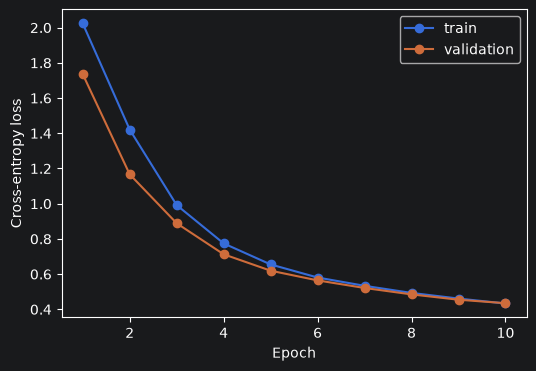

In [14]:
#训练和验证过程的loss曲线
epochs = [row['epoch'] for row in trainer.history]
loss = [row['loss'] for row in trainer.history]
val_loss = [row['val_loss'] for row in trainer.history]

fig = plt.figure(1, figsize=(6, 4))
ax = fig.add_subplot(1, 1, 1)
ax.plot(epochs, loss, marker='o')
ax.plot(epochs, val_loss, marker='o')
ax.set_xlabel('Epoch')
ax.set_ylabel('Cross-entropy loss')
ax.legend(['train', 'validation'])
plt.show()

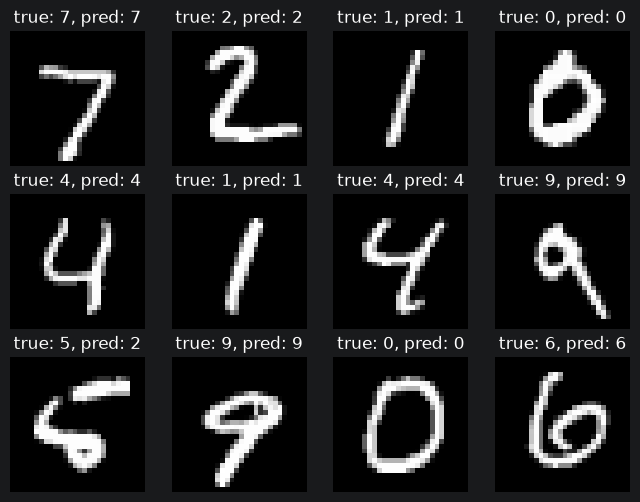

In [12]:
#随机查看一批图片的模型预测
model.eval()
images, labels = next(iter(test_dl))

with torch.inference_mode():
    logits = model(images.to(device))
    preds = logits.argmax(dim=1).cpu()

fig = plt.figure(2, figsize=(8, 6))
axes = fig.subplots(3, 4)
z = zip(axes.flat, images[:12], labels[:12], preds[:12], strict=True)
for ax, image, label, pred in z:
    true_label = label.item()
    pred_label = pred.item()
    ax.imshow(image.squeeze(0), cmap='gray', vmin=0, vmax=1)
    ax.axis('off')
    ax.set_title(f'true: {true_label}, pred: {pred_label}')
plt.show()